In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from shapely.geometry import box
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

DATA = Path("../../data/algemeen")
FIGUREN = Path("../../fig/H5")
FIGUREN.mkdir(exist_ok=True)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
from matplotlib.font_manager import FontProperties, findfont
print(findfont(FontProperties(family="serif")).split("/")[-1])  # enkel de bestandsnaam

LibertinusSerif-Regular.otf


In [4]:
GEB_MACRO = DATA / "gebeurtenisdata_macro"

bestanden = sorted(
    f for f in GEB_MACRO.glob("*.xlsx")
    if not f.name.startswith(("._", "~$"))
)
print(f"{len(bestanden)} bestanden gevonden\n")

197 bestanden gevonden



In [5]:
schemas = {}
for f in bestanden:
    try:
        schemas[f.name] = tuple(pd.read_excel(f, nrows=0, engine="openpyxl").columns)
    except Exception as e:
        print(f"niet gelezen: {f.name} ({type(e).__name__})")

print(f"{len(schemas)} bestanden, {len(set(schemas.values()))} verschillende schema's")

197 bestanden, 124 verschillende schema's


In [6]:
df = pd.concat(
    [pd.read_excel(GEB_MACRO / naam, engine="openpyxl").assign(bestand=naam) for naam in schemas],
    ignore_index=True,
)
print(f"{len(df):,} rijen, {df['bestand'].nunique()} bestanden")

# ruwe waarden van de genderkolom, inclusief ontbrekende
print("\ngender_inferred:")
print(df["gender_inferred"].value_counts(dropna=False))

# hoe hard is de toewijzing?
print("\nfirstname_match:")
print(df["firstname_match"].value_counts(dropna=False).head(10))

# eenheid van analyse: is elke rij één persoon in één incident?
print(f"\nunieke Person ID: {df['Person ID'].nunique():,}")
print(f"unieke Incident Number: {df['Incident Number'].nunique():,}")
print(f"dubbele Person ID: {df['Person ID'].duplicated().sum():,}")


383,125 rijen, 197 bestanden

gender_inferred:
gender_inferred
man          171903
unknown      158949
woman         51841
uncertain       432
Name: count, dtype: int64

firstname_match:
firstname_match
NaN       178021
Jan        11631
Frans      10935
Louis       6210
Petrus      6007
Maria       5472
Joseph      5143
Henri       4192
Jozef       4152
Karel       2807
Name: count, dtype: int64

unieke Person ID: 4,727
unieke Incident Number: 3,827
dubbele Person ID: 378,398


In [7]:
# ── Tabel 5.1 en 5.2: bruikbare waarden per onderzoekscategorie ─────────────
# Basis: alle personen met een genormaliseerde datum in 1876–1939.
# Ontbrekende en onbekende waarden tellen niet mee.
TABELLEN = Path("../../tab/H5")
TABELLEN.mkdir(parents=True, exist_ok=True)

basis = df[pd.to_datetime(df["E_DATE_clean"], errors="coerce").dt.year.between(1876, 1939)]
ONBEKEND = {"unknown", "onbekend", "", "nan", "none", "-", "?", "uncertain"}

def bruikbaar(kolom):
    tekst = basis[kolom].astype(str).str.strip().str.lower()
    return basis[kolom].notna() & ~tekst.isin(ONBEKEND)

def getal(kolom):
    return pd.to_numeric(basis[kolom], errors="coerce").notna()

categorieen = {
    "Persoon": pd.Series(True, index=basis.index),
    "Datum": pd.Series(True, index=basis.index),
    "Tijdstip": bruikbaar("E_TIME_clean"),
    "Plaatsnaam": bruikbaar("E_LOC_gis1898"),
    "Voornaam/gender": basis["gender_inferred"].isin(["man", "woman"]),
    "Geboortedatum": getal("P_BIRTHYEAR"),
    "Leeftijd": getal("P_AGE_clean"),
    "Geboorteplaats": bruikbaar("P_BIRTHPLACE_country"),
    "Beroep (HISCO)": bruikbaar("P_PROF_hisco"),
    "Klasse (HISCLASS)": bruikbaar("P_PROF_hisclass"),
}
n = len(basis)
tabel51 = pd.DataFrame({
    "na nabewerking": {k: int(v.sum()) for k, v in categorieen.items()},
    "aandeel (%)": {k: round(v.mean() * 100, 1) for k, v in categorieen.items()},
})

# cumulatief, van boven naar onder (geboorteplaats niet, zoals in Tabel 5.2)
cumulatief, samen = {}, pd.Series(True, index=basis.index)
for k in ["Persoon", "Datum", "Tijdstip", "Plaatsnaam", "Voornaam/gender",
          "Leeftijd", "Beroep (HISCO)", "Klasse (HISCLASS)"]:
    samen = samen & categorieen[k]
    cumulatief[k] = int(samen.sum())
tabel52 = pd.DataFrame({"cumulatief (absoluut)": cumulatief})
tabel52["cumulatief (%)"] = (tabel52["cumulatief (absoluut)"] / n * 100).round(1)

print(f"basis: {n:,} personen\n")
print(tabel51.to_string(), "\n")
print(tabel52.to_string())
tabel51.to_csv(TABELLEN / "5.1_waarden_per_categorie.csv", sep=";", decimal=",")
tabel52.to_csv(TABELLEN / "5.2_cumulatieve_waarden.csv", sep=";", decimal=",")


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_45149/152238336.py:7: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  basis = df[pd.to_datetime(df["E_DATE_clean"], errors="coerce").dt.year.between(1876, 1939)]


basis: 372,115 personen

                   na nabewerking  aandeel (%)
Persoon                    372115        100.0
Datum                      372115        100.0
Tijdstip                   192003         51.6
Plaatsnaam                 200919         54.0
Voornaam/gender            217725         58.5
Geboortedatum               79272         21.3
Leeftijd                   103794         27.9
Geboorteplaats              93029         25.0
Beroep (HISCO)              75697         20.3
Klasse (HISCLASS)           70115         18.8 

                   cumulatief (absoluut)  cumulatief (%)
Persoon                           372115           100.0
Datum                             372115           100.0
Tijdstip                          192003            51.6
Plaatsnaam                        138959            37.3
Voornaam/gender                    82625            22.2
Leeftijd                           38808            10.4
Beroep (HISCO)                     18717             5.0


217,725 persoonsvermeldingen met gender


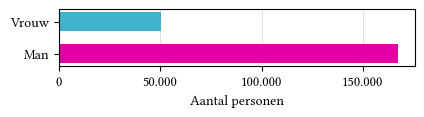

In [8]:
MAN, VROUW = KLEUR_MAN, KLEUR_VROUW
KLEUR = {"Man": MAN, "Vrouw": VROUW}

d = df[df["E_YEAR"].between(1876, 1939)].copy()
d = d[d["gender_inferred"].isin(["man", "woman"])]
d["gender"] = d["gender_inferred"].map({"man": "Man", "woman": "Vrouw"})
print(f"{len(d):,} persoonsvermeldingen met gender")

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.3))

telling = d["gender"].value_counts()
ax.barh(telling.index, telling.values,
        color=[KLEUR[g] for g in telling.index], height=0.6)
ax.xaxis.grid(True)
ax.set_xlabel("Aantal personen")
ax.set_ylabel("")
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(50000))
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", "."))
)

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.1_gender_verdeling.png", dpi=300, bbox_inches="tight")
plt.show()

3 jaren onder 200 vermeldingen: [1894, 1901, 1917]


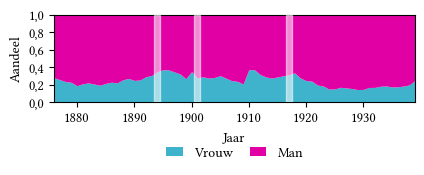

In [9]:
DREMPEL_G = 200

per_jaar = (
    d.groupby("E_YEAR")["gender"]
     .value_counts(normalize=True)
     .unstack()
     .reindex(columns=["Vrouw", "Man"])
)
n_jaar = d.groupby("E_YEAR").size()
dun_g = n_jaar[n_jaar < DREMPEL_G].index
print(f"{len(dun_g)} jaren onder {DREMPEL_G} vermeldingen: {list(dun_g)}")

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.5))

per_jaar.plot.area(ax=ax, linewidth=0, color=[KLEUR["Vrouw"], KLEUR["Man"]])

for jaar in dun_g:
    ax.axvspan(jaar - 0.5, jaar + 0.5, color="white", alpha=0.55, zorder=3)

ax.set_xlabel("Jaar")
ax.set_ylabel("Aandeel")
ax.set_ylim(0, 1)
ax.set_xlim(per_jaar.index.min(), per_jaar.index.max())
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}".replace(".", ",")))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xticks(range(1880, 1940, 10))
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=2,
          frameon=False, columnspacing=1.2, handlelength=1.2)

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.2_gender_per_jaar.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
print(df["P_PROF_hisclass"].value_counts(dropna=False).head(20))
print("\ntypes:", df["P_PROF_hisclass"].map(type).value_counts().to_dict())
print(f"dekking: {df['P_PROF_hisclass'].notna().mean():.1%}")

P_PROF_hisclass
NaN        295814
9           21602
unknown     15130
11          13297
7           10662
4            9477
3            4854
2            3836
1            3172
5            2783
8            1348
6             779
12            315
10             56
Name: count, dtype: int64

types: {<class 'float'>: 295818, <class 'int'>: 72177, <class 'str'>: 15130}
dekking: 22.8%


In [11]:
# ── hercodering herbergiers ───────────────────────────────────────────────
hisco = pd.to_numeric(df["P_PROF_hisco"], errors="coerce")
df.loc[hisco == 51020, "P_PROF_hisclass"] = 4
print(f"{(hisco == 51020).sum():,} vermeldingen op HISCLASS 4 gezet")


2,580 vermeldingen op HISCLASS 4 gezet


In [12]:
# ── basisselectie ─────────────────────────────────────────────────────────
d = df[df["E_YEAR"].between(1876, 1939)].copy()
d = d[d["gender_inferred"].isin(["man", "woman"])]
d["gender"] = d["gender_inferred"].map({"man": "Man", "woman": "Vrouw"})



In [13]:
# ── klasse ────────────────────────────────────────────────────────────────
HISCLASS_GROEP = {
    1: "Elite", 2: "Elite",
    3: "Middenklasse", 4: "Middenklasse", 5: "Middenklasse",
    6: "Geschoolde arbeid", 7: "Geschoolde arbeid",
    8: "Laaggeschoolde arbeid", 9: "Laaggeschoolde arbeid", 10: "Laaggeschoolde arbeid",
    11: "Ongeschoolde arbeid", 12: "Ongeschoolde arbeid",
}
VOLGORDE = ["Elite", "Middenklasse", "Geschoolde arbeid",
            "Laaggeschoolde arbeid", "Ongeschoolde arbeid"]

klassedata = d.copy()
klassedata["hisclass_num"] = pd.to_numeric(klassedata["P_PROF_hisclass"], errors="coerce")
klassedata["klasse"] = klassedata["hisclass_num"].map(HISCLASS_GROEP)
klassedata = klassedata[klassedata["klasse"].notna()]
print(f"{len(klassedata):,} vermeldingen met klasse")

n_gender = (
    klassedata.groupby(["klasse", "gender"]).size()
     .unstack().reindex(index=VOLGORDE, columns=["Vrouw", "Man"])
)
per_klasse = (
    klassedata.groupby("klasse")["gender"]
     .value_counts(normalize=True)
     .unstack().reindex(index=VOLGORDE, columns=["Vrouw", "Man"])
)
print(per_klasse.round(3))

48,502 vermeldingen met klasse
gender                 Vrouw    Man
klasse                             
Elite                  0.096  0.904
Middenklasse           0.159  0.841
Geschoolde arbeid      0.106  0.894
Laaggeschoolde arbeid  0.076  0.924
Ongeschoolde arbeid    0.393  0.607


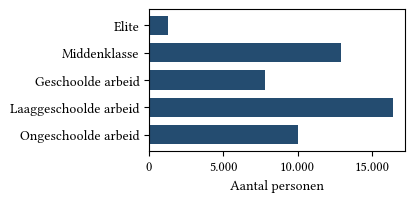

In [14]:
n_klasse = klassedata["klasse"].value_counts().reindex(VOLGORDE)

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.5))
ax.barh(VOLGORDE, n_klasse.values, color="#244C70", height=0.7)
ax.invert_yaxis()
ax.set_xlabel("Aantal personen")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", ".")))

plt.tight_layout()
plt.show()

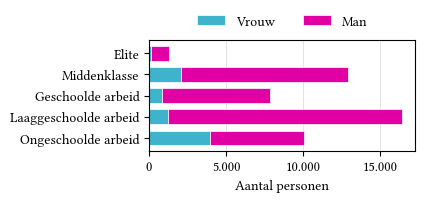

In [15]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.5))
n_gender.plot.barh(ax=ax, stacked=True, color=[KLEUR["Vrouw"], KLEUR["Man"]],
                   width=0.7, edgecolor="white", linewidth=0.5)
ax.invert_yaxis()
ax.xaxis.grid(True)
ax.set_xlabel("Aantal personen")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", ".")))
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)  # boven de grafiek

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.5_klasse_gestapeld.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
n_klasse_totaal = len(klassedata)
n_gegenderd = len(d)

print(f"N klasse: {n_klasse_totaal:,}")
print(f"aandeel van gegenderde vermeldingen: {n_klasse_totaal / n_gegenderd:.1%}")
print(klassedata.groupby("gender").size())
print(klassedata.groupby("klasse", observed=True).size().reindex(VOLGORDE))

N klasse: 48,502
aandeel van gegenderde vermeldingen: 22.3%
gender
Man      40305
Vrouw     8197
dtype: int64
klasse
Elite                     1296
Middenklasse             12898
Geschoolde arbeid         7835
Laaggeschoolde arbeid    16423
Ongeschoolde arbeid      10050
dtype: int64


In [17]:
for label in VOLGORDE:
    sub = klassedata[klassedata["klasse"] == label]
    print(f"\n=== {label} — {len(sub):,} ({sub['gender'].eq('Vrouw').mean():.1%} vrouw) ===")
    top = (
        sub.groupby(["P_PROF_hisco", "hisclass_num"])
           .agg(n=("gender", "size"), aandeel_vrouw=("gender", lambda g: g.eq("Vrouw").mean()))
           .sort_values("n", ascending=False)
           .head(8)
    )
    print(top.round(3))


=== Elite — 1,296 (9.6% vrouw) ===
                             n  aandeel_vrouw
P_PROF_hisco hisclass_num                    
06105        2.0           426          0.150
21110        1.0           169          0.065
02000        2.0           116          0.034
12110        2.0            92          0.033
06710        2.0            72          0.083
12310        2.0            57          0.053
58320        1.0            56          0.054
15915        2.0            31          0.097

=== Middenklasse — 12,898 (15.9% vrouw) ===
                              n  aandeel_vrouw
P_PROF_hisco hisclass_num                     
41025        4.0           2643          0.072
21240        3.0           2338          0.034
51020        4.0           1785          0.389
41030        4.0           1091          0.260
30000        5.0            561          0.046
45125        5.0            417          0.573
43220        4.0            398          0.055
44130        4.0            331     

7 jaren onder 200 vermeldingen: [1894, 1898, 1899, 1901, 1905, 1917, 1918]


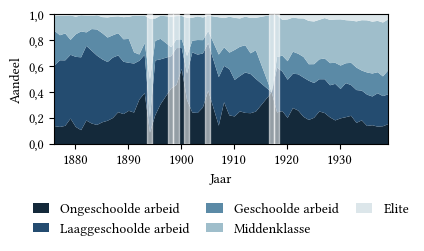

In [18]:
DREMPEL = 200

VOLGORDE_OMGEKEERD = VOLGORDE[::-1]

per_jaar_klasse = (
    klassedata.groupby("E_YEAR")["klasse"]
      .value_counts(normalize=True)
      .unstack()
      .reindex(columns=VOLGORDE_OMGEKEERD)
)
n_jaar_k = klassedata.groupby("E_YEAR").size()
dun = n_jaar_k[n_jaar_k < DREMPEL].index
print(f"{len(dun)} jaren onder {DREMPEL} vermeldingen: {list(dun)}")

KLASSE_KLEUREN = ["#14293A", "#244C70", "#5B8AA6", "#9FBECB", "#DCE6EA"]

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.7))

per_jaar_klasse.plot.area(ax=ax, linewidth=0, color=KLASSE_KLEUREN)

for jaar in dun:
    ax.axvspan(jaar - 0.5, jaar + 0.5, color="white", alpha=0.55, zorder=3)

ax.set_xlabel("Jaar")
ax.set_ylabel("Aandeel")
ax.set_ylim(0, 1)
ax.set_xlim(per_jaar_klasse.index.min(), per_jaar_klasse.index.max())
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}".replace(".", ",")))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xticks(range(1880, 1940, 10))
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=3,
          frameon=False, columnspacing=1.2, handlelength=1.2)

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.6_klasse_per_jaar.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
print(d["P_AGE_categories"].value_counts(dropna=False))
print()
print(pd.to_numeric(d["P_AGE_clean"], errors="coerce").describe())
print(f"\ndekking P_AGE_clean: {pd.to_numeric(d['P_AGE_clean'], errors='coerce').notna().mean():.1%}")
print(d.groupby("gender")["P_AGE_clean"].apply(lambda s: pd.to_numeric(s, errors='coerce').notna().mean()).round(3))

P_AGE_categories
NaN               136637
volwassene         56279
jongvolwassene     18080
kind                3788
oudere              2403
jong kind            538
Name: count, dtype: int64

count    81088.000000
mean        34.195763
std         14.408983
min          0.000000
25%         24.000000
50%         32.000000
75%         43.000000
max        100.000000
Name: P_AGE_clean, dtype: float64

dekking P_AGE_clean: 37.2%
gender
Man      0.378
Vrouw    0.354
Name: P_AGE_clean, dtype: float64


80,920 vermeldingen met leeftijd


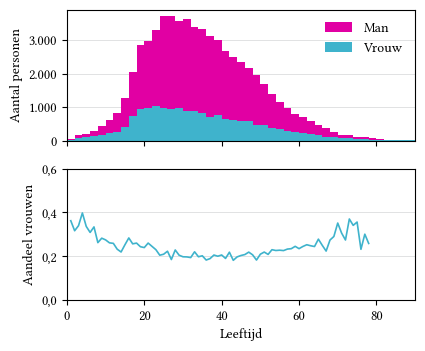

In [20]:
leeftijd = d.copy()
leeftijd["leeftijd"] = pd.to_numeric(leeftijd["P_AGE_clean"], errors="coerce")
leeftijd = leeftijd[leeftijd["leeftijd"].between(1, 90)]
print(f"{len(leeftijd):,} vermeldingen met leeftijd")

per_leeftijd = (
    leeftijd.groupby("leeftijd")["gender"]
      .apply(lambda g: g.eq("Vrouw").mean())
)
n_leeftijd = leeftijd.groupby("leeftijd").size()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.85),
    sharex=True,
)

bins = range(0, 92, 2)
for g in ["Man", "Vrouw"]:
    ax1.hist(leeftijd.loc[leeftijd["gender"] == g, "leeftijd"],
             bins=bins, color=KLEUR[g], label=g)
ax1.set_ylabel("Aantal personen")
ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", "."))
)
ax1.legend(title="", frameon=False)

ax2.plot(per_leeftijd.index, per_leeftijd.where(n_leeftijd >= 50),
         color=VROUW, linewidth=1.2)
ax1.yaxis.grid(True)
ax2.yaxis.grid(True)
ax2.set_xlim(0, 90)
ax2.set_ylim(0, 0.6)
ax2.set_xlabel("Leeftijd")
ax2.set_ylabel("Aandeel vrouwen")
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:.1f}".replace(".", ","))
)

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.3_leeftijd_verdeling.png", dpi=300, bbox_inches="tight")
plt.show()

81,088 vermeldingen met leeftijdscategorie
                   min    max  count
P_AGE_categories                    
jong kind          0.0    4.0    538
kind               5.0   14.0   3788
jongvolwassene    15.0   24.0  18080
volwassene        25.0   64.0  56279
oudere            65.0  100.0   2403

6 jaren onder 200: [1894, 1898, 1901, 1905, 1917, 1918]


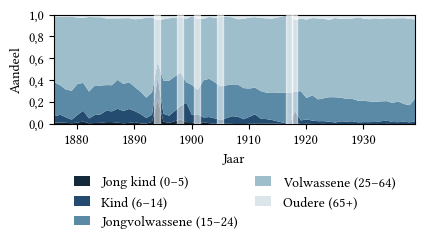

In [21]:
CATS = ["jong kind", "kind", "jongvolwassene", "volwassene", "oudere"]
CAT_LABELS = {
    "jong kind": "Jong kind (0–5)",
    "kind": "Kind (6–14)",
    "jongvolwassene": "Jongvolwassene (15–24)",
    "volwassene": "Volwassene (25–64)",
    "oudere": "Oudere (65+)",
}
LEEFTIJD_KLEUREN = ["#14293A", "#244C70", "#5B8AA6", "#9FBECB", "#DCE6EA"]
DREMPEL_L = 200

leeftijdcat = d[d["P_AGE_categories"].notna()].copy()
print(f"{len(leeftijdcat):,} vermeldingen met leeftijdscategorie")

# controle van de grenzen
print(
    leeftijdcat
      .assign(lft=pd.to_numeric(leeftijdcat["P_AGE_clean"], errors="coerce"))
      .groupby("P_AGE_categories")["lft"]
      .agg(["min", "max", "count"])
      .reindex(CATS)
)

per_jaar_leeftijd = (
    leeftijdcat.groupby("E_YEAR")["P_AGE_categories"]
      .value_counts(normalize=True)
      .unstack()
      .reindex(columns=CATS)
)
per_jaar_leeftijd.columns = [CAT_LABELS[c] for c in CATS]

n_jaar_l = leeftijdcat.groupby("E_YEAR").size()
dun_l = n_jaar_l[n_jaar_l < DREMPEL_L].index
print(f"\n{len(dun_l)} jaren onder {DREMPEL_L}: {list(dun_l)}")

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.7))

per_jaar_leeftijd.plot.area(ax=ax, linewidth=0, color=LEEFTIJD_KLEUREN)

for jaar in dun_l:
    ax.axvspan(jaar - 0.5, jaar + 0.5, color="white", alpha=0.55, zorder=3)

ax.set_xlabel("Jaar")
ax.set_ylabel("Aandeel")
ax.set_ylim(0, 1)
ax.set_xlim(per_jaar_leeftijd.index.min(), per_jaar_leeftijd.index.max())
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}".replace(".", ",")))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xticks(range(1880, 1940, 10))
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=2,
          frameon=False, columnspacing=1.2, handlelength=1.2)

plt.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig(FIGUREN / "5.4_leeftijd_per_jaar.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
from scipy.stats import chi2_contingency

def cramers_v(data, kolom, minimum=1000):
    """Cramérs V voor kolom × wijk, met kleine wijken uitgesloten."""
    sub = data[data[kolom].notna()]
    groot = sub["district"].value_counts()
    groot = groot[groot >= minimum].index
    sub = sub[sub["district"].isin(groot)]

    tabel = pd.crosstab(sub["district"], sub[kolom])
    chi2, p, dof, _ = chi2_contingency(tabel)
    n = tabel.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabel.shape) - 1)))
    return {
        "variabele": kolom,
        "wijken": tabel.shape[0],
        "n": n,
        "chi2": round(chi2, 1),
        "dof": dof,
        "p": p,
        "cramers_v": round(v, 3),
    }

resultaten = pd.DataFrame([
    cramers_v(d, "gender"),
    cramers_v(klassedata, "klasse"),
    cramers_v(leeftijdcat, "P_AGE_categories"),
])
print(resultaten.to_string(index=False))

       variabele  wijken      n   chi2  dof             p  cramers_v
          gender       8 217175 3636.1    7  0.000000e+00      0.129
          klasse       7  47682 2122.7   24  0.000000e+00      0.105
P_AGE_categories       7  79795  803.3   24 4.117733e-154      0.050
